In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("/content/Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Column Names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     704

In [12]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [13]:
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [14]:
df.drop('customerID', axis=1, inplace=True)

In [15]:
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


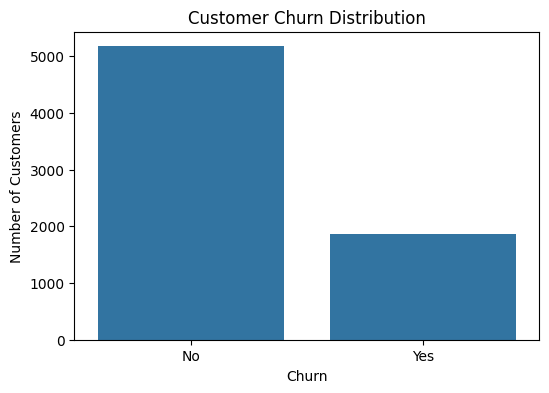

In [16]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

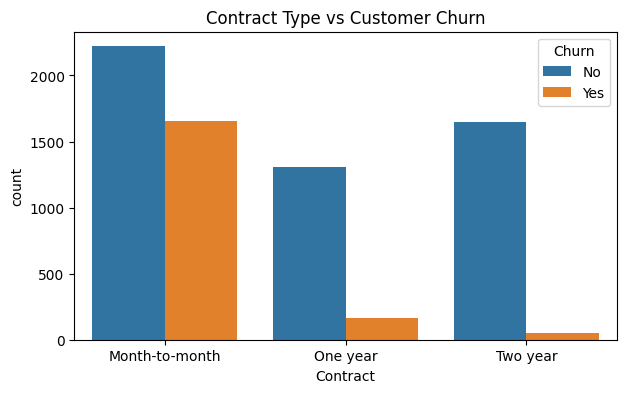

In [17]:
plt.figure(figsize=(7,4))

sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Contract Type vs Customer Churn')

plt.show()

In [18]:
X = df.drop('Churn', axis=1)

y = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [21]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X_train.select_dtypes(
    include=['object']
).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [22]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [23]:
smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

In [24]:
rf_model = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

In [25]:
rf_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_...
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 RandomForestClassifier(max_depth=15, min_samples_split=5,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [26]:
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

In [27]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")

print(classification_report(
    y_test,
    rf_predictions
))

rf_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest Accuracy: 0.7721788502484032

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409

Random Forest ROC-AUC: 0.8301867782686196


**XGBoost Classifier**

In [28]:
xgb_model = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

In [29]:
xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [30]:
xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

In [31]:
print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_predictions))

print("\nClassification Report:")

print(classification_report(
    y_test,
    xgb_predictions
))

xgb_auc = roc_auc_score(
    y_test,
    xgb_probabilities
)

print("XGBoost ROC-AUC:", xgb_auc)

XGBoost Accuracy: 0.7799858055358411

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1035
           1       0.58      0.62      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409

XGBoost ROC-AUC: 0.8383373375700741


***For RandomForest***

In [32]:
rf_cv = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv)

print("Random Forest Mean CV ROC-AUC:",
      rf_cv.mean())

Random Forest CV Scores: [0.85300438 0.84294064 0.83703327 0.82648684 0.81724855]
Random Forest Mean CV ROC-AUC: 0.8353427344898442


***For XGBoost***

In [33]:
xgb_cv = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("XGBoost CV Scores:", xgb_cv)

print("XGBoost Mean CV ROC-AUC:",
      xgb_cv.mean())

XGBoost CV Scores: [0.86254302 0.85243283 0.84507941 0.83142884 0.82456233]
XGBoost Mean CV ROC-AUC: 0.8432092838733212


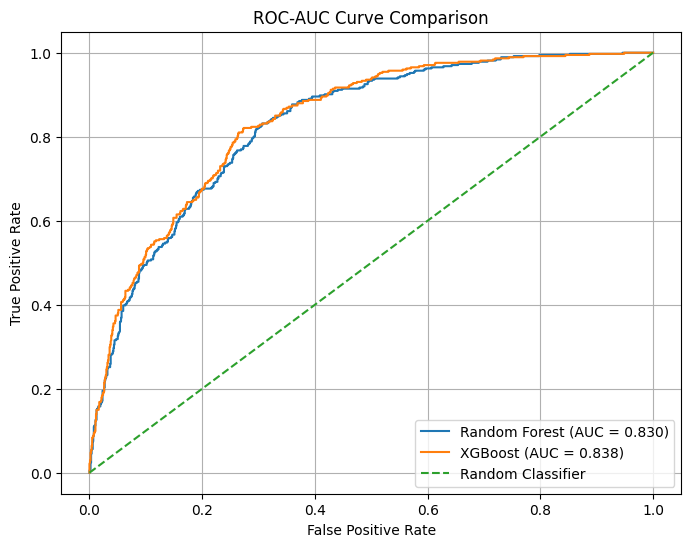

In [34]:
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_probabilities
)

plt.figure(figsize=(8,6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend()
plt.grid()

plt.show()

**Confusion Matrix for RF**

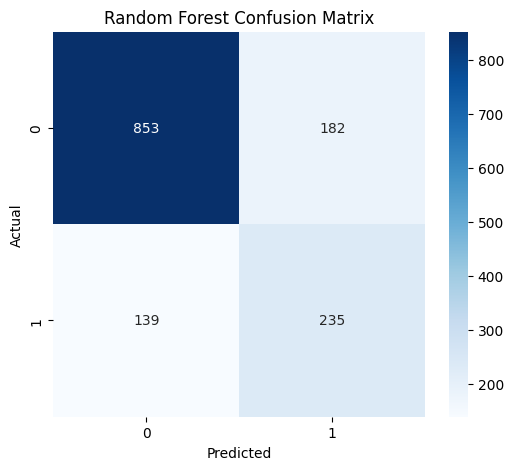

In [35]:
rf_cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

**Confusion Matrix for XGBoost**

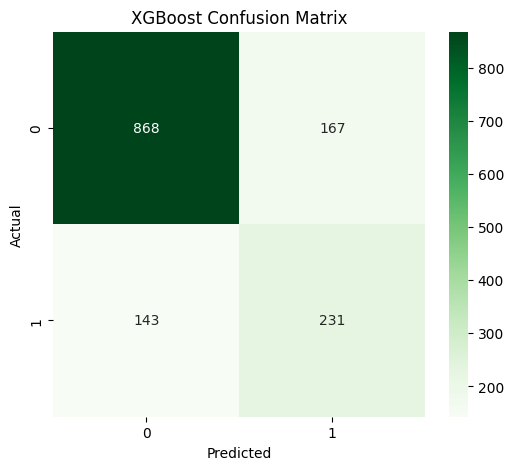

In [36]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [37]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],

    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],

    'ROC-AUC': [
        rf_auc,
        xgb_auc
    ],

    'Cross Validation ROC-AUC': [
        rf_cv.mean(),
        xgb_cv.mean()
    ]
})

print(results)

           Model  Accuracy   ROC-AUC  Cross Validation ROC-AUC
0  Random Forest  0.772179  0.830187                  0.835343
1        XGBoost  0.779986  0.838337                  0.843209


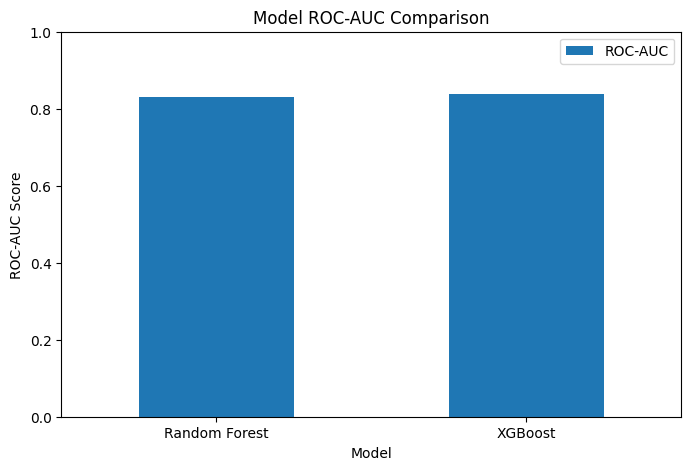

In [38]:
results.set_index('Model')[['ROC-AUC']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Model ROC-AUC Comparison')
plt.ylabel('ROC-AUC Score')
plt.ylim(0,1)
plt.xticks(rotation=0)

plt.show()

In [39]:
# Get feature names after preprocessing

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

rf_importance = rf_model.named_steps[
    'classifier'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

top10_features = importance_df.head(10)

print(top10_features)

                                Feature  Importance
36         cat__Contract_Month-to-month    0.102978
1                           num__tenure    0.101619
3                     num__TotalCharges    0.083833
2                   num__MonthlyCharges    0.069852
18               cat__OnlineSecurity_No    0.065972
43  cat__PaymentMethod_Electronic check    0.056426
38               cat__Contract_Two year    0.047548
27                  cat__TechSupport_No    0.044780
16     cat__InternetService_Fiber optic    0.032968
40            cat__PaperlessBilling_Yes    0.023843


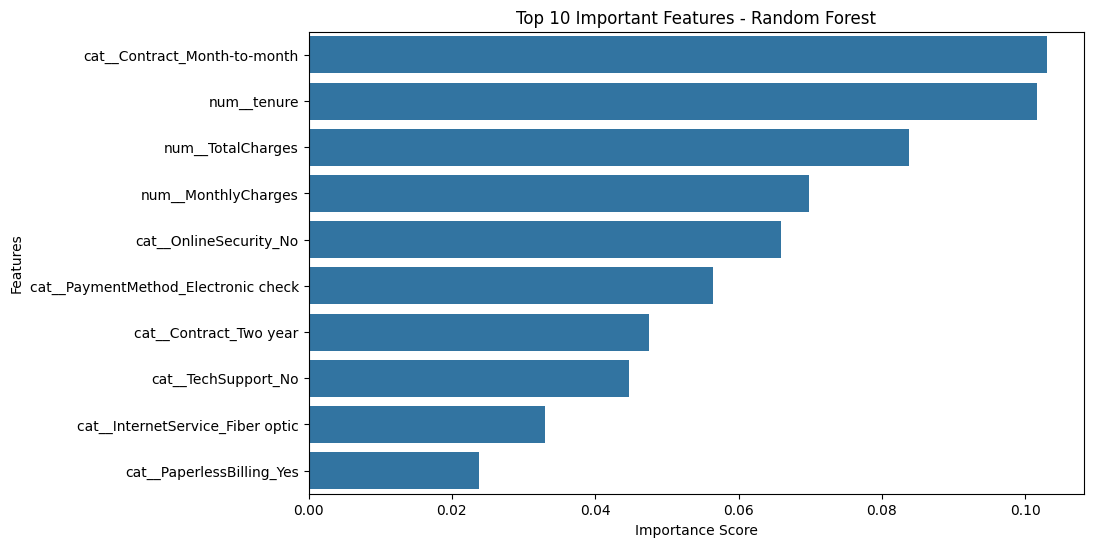

In [42]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top10_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

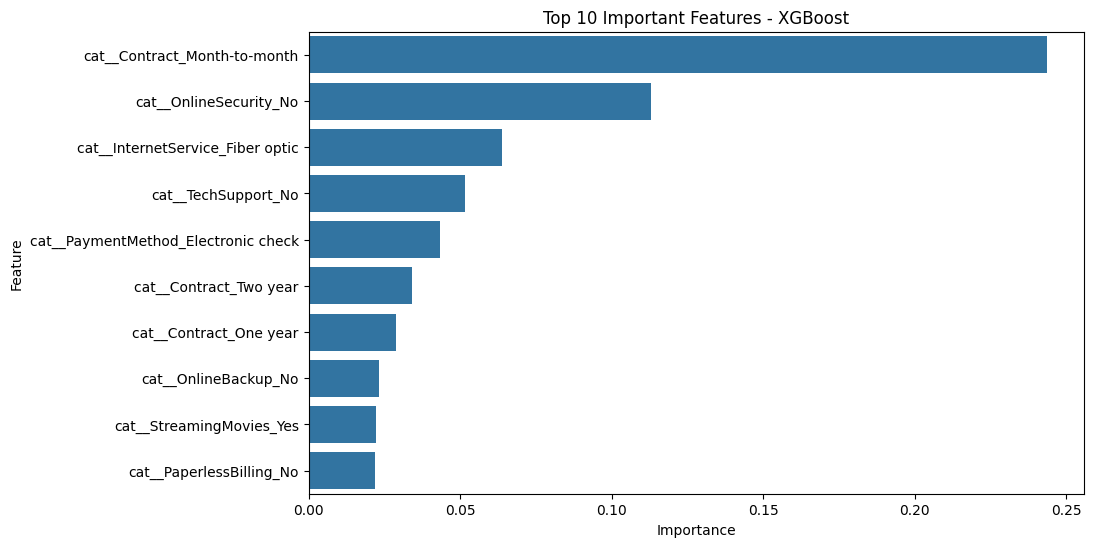

In [43]:
xgb_importance = xgb_model.named_steps[
    'classifier'
].feature_importances_

xgb_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_importance
})

xgb_importance_df = xgb_importance_df.sort_values(
    by='Importance',
    ascending=False
)

top10_xgb = xgb_importance_df.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10_xgb,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - XGBoost')

plt.show()

In [44]:
import joblib

if rf_auc >= xgb_auc:

    best_model = rf_model
    best_model_name = 'Random Forest'

else:

    best_model = xgb_model
    best_model_name = 'XGBoost'

joblib.dump(best_model, 'best_churn_model.pkl')

print("Best Model:", best_model_name)

Best Model: XGBoost


In [45]:
loaded_model = joblib.load('best_churn_model.pkl')

In [49]:
new_customer2 = new_customer.copy()

new_customer2['tenure'] = 60
new_customer2['Contract'] = 'Two year'
new_customer2['MonthlyCharges'] = 50.00
new_customer2['TotalCharges'] = 3000.00
new_customer2['OnlineSecurity'] = 'Yes'
new_customer2['TechSupport'] = 'Yes'

prediction2 = model.predict(new_customer2)

probability2 = model.predict_proba(new_customer2)[0][1]

print("Prediction:",
      "Will Leave" if prediction2[0] == 1 else "Will Stay")

print("Churn Probability:",
      round(probability2 * 100, 2), "%")

Prediction: Will Stay
Churn Probability: 4.32 %


In [51]:
from google.colab import files
files.download('best_churn_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>